# IaCGen with its default feedback schedule and 19 iterations against IaCGen with moderate feedback, IaCGen-MAS and zero-shot (DeepSeek-V4-Flash, CloudFormation)

## Setup

In [1]:
import sys, re, csv, math, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")
csv.field_size_limit(sys.maxsize)
sys.path.insert(0, "audit")
import finalize_results as fr

FINAL = Path("../results"); DATA = Path("../data"); RES = Path("result/final")
FIG = Path("plots/iacgen_i19"); FIG.mkdir(parents=True, exist_ok=True)
OUT = RES
plt.style.use("ggplot"); sns.set_palette("muted")
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 90)

I19 = "CFN_RealAWS_IaCGen_DSV4Flash_i19"
MOD = "CFN_RealAWS_IaCGen_DSV4Flash"
SYSTEMS = {
    "IaCGen, default schedule": I19,
    "IaCGen, moderate feedback": MOD,
    "IaCGen-MAS": "CFN_RealAWS_DSV4F",
    "Zero-shot": "CFN_RealAWS_OneShot_DSV4F",
}
ORDER = list(SYSTEMS)
IACGEN = ORDER[:2]
PALETTE = dict(zip(ORDER, sns.color_palette("muted", len(ORDER))))
LV = [1, 2, 3, 4, 5]

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)

def holm(pvals):
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj

def mcnemar_exact(a, b):
    a = np.asarray(a, bool); b = np.asarray(b, bool)
    only_a = int((a & ~b).sum()); only_b = int((~a & b).sum())
    n = only_a + only_b
    p = 1.0 if n == 0 else stats.binomtest(min(only_a, only_b), n, 0.5).pvalue
    return dict(both=int((a & b).sum()), only_first=only_a, only_second=only_b, neither=int((~a & ~b).sum()), p=p)

## Load the results

In [2]:
bench = pd.read_csv(DATA / "cfn_eval_benchmark_real_aws.csv").drop_duplicates("row_number").set_index("row_number")
dcol = "difficulty" if "difficulty" in bench else "difficulty_level"

def severe_by_run(e):
    t = pd.read_csv(RES / f"Trivy_{e}.csv", engine="python").drop_duplicates("run_id")
    t = t[t.total_checks.notna()]
    return t.set_index("run_id").pipe(lambda x: (x.severity_critical_failed.fillna(0) + x.severity_high_failed.fillna(0)) > 0)

frames = []
for name, e in SYSTEMS.items():
    r = pd.read_csv(FINAL / e / "results_final.csv", engine="python")
    r["system"] = name; r["exp"] = e
    r["difficulty"] = r.row_number.map(bench[dcol])
    r["ok"] = r.final_validation_passed.astype(str).str.lower().eq("true")
    r["valid"] = ~r.validity.astype(str).str.startswith("invalid")
    if name in IACGEN:
        sev = severe_by_run(e)
        r["deploys"] = r.ok
        r["passed"] = r.ok & r.run_id.map(sev).eq(False)
    else:
        r["deploys"] = np.nan
        r["passed"] = r.ok
    frames.append(r)
runs = pd.concat(frames, ignore_index=True)
runs["system"] = pd.Categorical(runs.system, ORDER, ordered=True)
runs.groupby("system", observed=True).agg(rows=("row_number", "size"), deploys=("deploys", lambda s: s.sum(min_count=1)), passed=("passed", "sum"),
                                          invalid=("valid", lambda s: int((~s).sum())), max_iterations=("iterations_used", "max"))

,rows,deploys,passed,invalid,max_iterations
system,,,,,
"IaCGen, default schedule",250,207.0,168,3,17.0
"IaCGen, moderate feedback",250,219.0,181,3,15.0
IaCGen-MAS,250,NaN,247,1,15.0
Zero-shot,250,NaN,97,6,1.0


## Pass rate

In [3]:
rows = []
for name, g in runs.groupby("system", observed=True, sort=False):
    for crit in ("deploys", "passed"):
        if g[crit].isna().all():
            continue
        k = int(g[crit].astype(bool).sum())
        lo, hi = wilson(k, len(g))
        v = g[g.valid]
        rows.append(dict(system=name, criterion="deploys" if crit == "deploys" else "deployable and secure", rows=len(g), passed=k,
                         pass_rate=k / len(g), ci_lo=lo, ci_hi=hi, valid_rows=len(v), pass_rate_valid=v[crit].astype(bool).mean(),
                         first_attempt=int((g[crit].astype(bool) & (g.iterations_used == 1)).sum()),
                         mean_iterations=g.iterations_used.mean(), mean_iterations_passed=g.loc[g[crit].astype(bool), "iterations_used"].mean()))
HEAD = pd.DataFrame(rows)
HEAD.round(4)

,system,criterion,rows,passed,pass_rate,ci_lo,ci_hi,valid_rows,pass_rate_valid,first_attempt,mean_iterations,mean_iterations_passed
0,"IaCGen, default schedule",deploys,250,207,0.828,0.7763,0.8697,247,0.8381,57,5.728,4.7729
1,"IaCGen, default schedule",deployable and secure,250,168,0.672,0.6116,0.7272,247,0.6802,46,5.728,4.6726
2,"IaCGen, moderate feedback",deploys,250,219,0.876,0.8294,0.9113,247,0.8866,59,4.800,3.3562
3,"IaCGen, moderate feedback",deployable and secure,250,181,0.724,0.6655,0.7757,247,0.7328,50,4.800,3.3149
4,IaCGen-MAS,deployable and secure,250,247,0.988,0.9653,0.9959,249,0.9920,48,3.844,3.7085
5,Zero-shot,deployable and secure,250,97,0.388,0.3297,0.4497,244,0.3975,97,1.000,1.0000


## Pass rate by difficulty level

,L1,L2,L3,L4,L5,criterion
"IaCGen, default schedule",86.0,92.0,78.0,76.0,82.0,deploys
"IaCGen, moderate feedback",88.0,92.0,80.0,86.0,92.0,deploys
IaCGen-MAS,96.0,100.0,100.0,100.0,98.0,deployable and secure
Zero-shot,54.0,56.0,36.0,22.0,26.0,deployable and secure


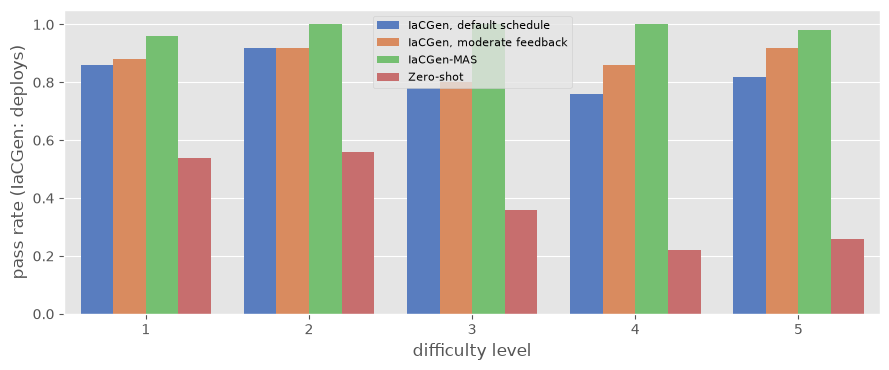

In [4]:
crit_col = lambda g: g.deploys.astype(bool) if g.system.iloc[0] in IACGEN else g.passed
LEVEL = pd.concat({name: runs[runs.system == name].pipe(lambda g: crit_col(g).groupby(g.difficulty).mean().mul(100).round(1))
                   for name in ORDER}, axis=1).T
LEVEL.columns = [f"L{c}" for c in LEVEL.columns]
LEVEL["criterion"] = ["deploys" if n in IACGEN else "deployable and secure" for n in LEVEL.index]
display(LEVEL)
fig, ax = plt.subplots(figsize=(9, 3.8))
d = pd.concat([runs[runs.system == n].assign(p=lambda g: crit_col(g).astype(float)) for n in ORDER])
sns.barplot(data=d, x="difficulty", y="p", hue="system", hue_order=ORDER, palette=PALETTE, ax=ax, errorbar=None)
ax.set_xlabel("difficulty level"); ax.set_ylabel("pass rate (IaCGen: deploys)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "pass_by_level.png", dpi=160); plt.show()

## passItr@n

n,1,2,3,5,8,10,15,19
"IaCGen, default schedule, deploys",22.8,27.2,30.0,52.8,67.2,79.2,82.8,82.8
"IaCGen, default schedule, deployable and secure",18.4,22.0,24.0,44.0,55.6,65.2,67.2,67.2
"IaCGen, moderate feedback, deploys",23.6,44.8,58.4,76.4,80.8,83.2,87.6,87.6
"IaCGen, moderate feedback, deployable and secure",20.0,37.2,48.8,63.2,66.8,68.8,72.4,72.4
"IaCGen-MAS, deployable and secure",19.2,47.6,62.4,80.0,90.4,93.2,98.8,98.8
"Zero-shot, deployable and secure",38.8,38.8,38.8,38.8,38.8,38.8,38.8,38.8


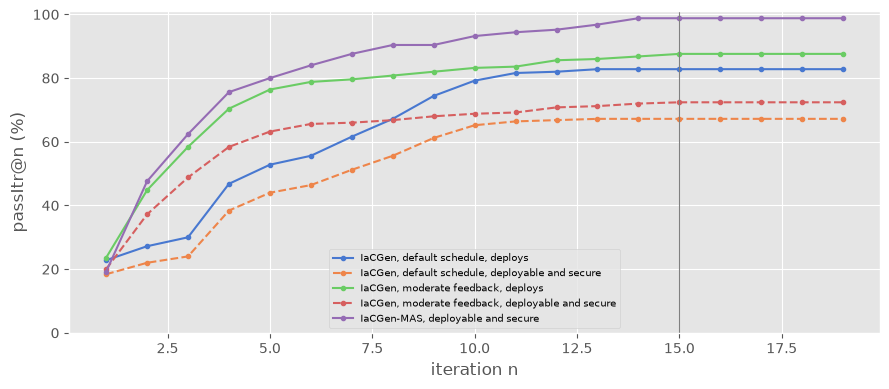

In [5]:
N = np.arange(1, 20)
cv = {}
for name in ORDER:
    g = runs[runs.system == name]
    for crit in ("deploys", "passed"):
        if g[crit].isna().all():
            continue
        ok = g[crit].astype(bool)
        lab = f"{name}, {'deploys' if crit == 'deploys' else 'deployable and secure'}"
        cv[lab] = [100 * (ok & (g.iterations_used <= n)).mean() for n in N]
CURVE = pd.DataFrame(cv, index=pd.Index(N, name="n")).round(1)
display(CURVE.loc[[1, 2, 3, 5, 8, 10, 15, 19]].T)
fig, ax = plt.subplots(figsize=(9, 4))
for c in CURVE.columns:
    if "Zero-shot" in c:
        continue
    ax.plot(CURVE.index, CURVE[c], marker="o", ms=3, label=c, ls="--" if "secure" in c and "IaCGen," in c else "-")
ax.axvline(15, color="grey", lw=0.8)
ax.set_xlabel("iteration n"); ax.set_ylabel("passItr@n (%)"); ax.set_ylim(0, 101); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "passitr_curve.png", dpi=160); plt.show()

## Paired comparisons

In [6]:
R = {n: runs[runs.system == n].set_index("row_number") for n in ORDER}
spec = [("IaCGen, default schedule", "deploys", "IaCGen, moderate feedback", "deploys"),
        ("IaCGen, default schedule", "passed", "IaCGen, moderate feedback", "passed"),
        ("IaCGen, default schedule", "deploys", "IaCGen-MAS", "passed"),
        ("IaCGen, default schedule", "passed", "IaCGen-MAS", "passed"),
        ("IaCGen, default schedule", "deploys", "Zero-shot", "passed")]
pairs = []
for a, ca, b, cb in spec:
    for scope in ("all rows", "common valid rows"):
        idx = R[a].index.intersection(R[b].index)
        if scope == "common valid rows":
            idx = [i for i in idx if R[a].loc[i, "valid"] and R[b].loc[i, "valid"]]
        x = R[a].loc[idx, ca].astype(bool).values; y = R[b].loc[idx, cb].astype(bool).values
        m = mcnemar_exact(x, y)
        pairs.append(dict(first=a, first_criterion=ca, second=b, second_criterion=cb, scope=scope, rows=len(idx), first_pass=int(x.sum()), second_pass=int(y.sum()),
                          only_first=m["only_first"], only_second=m["only_second"], p=m["p"]))
PAIRS = pd.DataFrame(pairs).replace({"passed": "deployable and secure"})
PAIRS["p_holm"] = np.nan
for s in PAIRS.scope.unique():
    PAIRS.loc[PAIRS.scope == s, "p_holm"] = holm(PAIRS.loc[PAIRS.scope == s, "p"].values)
PAIRS.round(4)

,first,first_criterion,second,second_criterion,scope,rows,first_pass,second_pass,only_first,only_second,p,p_holm
0,"IaCGen, default schedule",deploys,"IaCGen, moderate feedback",deploys,all rows,250,207,219,13,25,0.0730,0.1320
1,"IaCGen, default schedule",deploys,"IaCGen, moderate feedback",deploys,common valid rows,246,206,218,12,24,0.0652,0.1192
2,"IaCGen, default schedule",deployable and secure,"IaCGen, moderate feedback",deployable and secure,all rows,250,168,181,15,28,0.0660,0.1320
3,"IaCGen, default schedule",deployable and secure,"IaCGen, moderate feedback",deployable and secure,common valid rows,246,167,180,14,27,0.0596,0.1192
4,"IaCGen, default schedule",deploys,IaCGen-MAS,deployable and secure,all rows,250,207,247,0,40,0.0000,0.0000
5,"IaCGen, default schedule",deploys,IaCGen-MAS,deployable and secure,common valid rows,247,207,245,0,38,0.0000,0.0000
6,"IaCGen, default schedule",deployable and secure,IaCGen-MAS,deployable and secure,all rows,250,168,247,0,79,0.0000,0.0000
7,"IaCGen, default schedule",deployable and secure,IaCGen-MAS,deployable and secure,common valid rows,247,168,245,0,77,0.0000,0.0000
8,"IaCGen, default schedule",deploys,Zero-shot,deployable and secure,all rows,250,207,97,119,9,0.0000,0.0000
9,"IaCGen, default schedule",deploys,Zero-shot,deployable and secure,common valid rows,242,205,97,117,9,0.0000,0.0000


In [7]:
a = R["IaCGen, default schedule"]; b = R["IaCGen, moderate feedback"]
idx = a.index.intersection(b.index)
dis = pd.DataFrame({"difficulty": a.loc[idx, "difficulty"], "default_deploys": a.loc[idx, "deploys"].astype(bool), "moderate_deploys": b.loc[idx, "deploys"].astype(bool),
                    "default_iterations": a.loc[idx, "iterations_used"], "moderate_iterations": b.loc[idx, "iterations_used"],
                    "default_validity": a.loc[idx, "validity"], "moderate_validity": b.loc[idx, "validity"]})
DISAGREE = dis[dis.default_deploys != dis.moderate_deploys].sort_values(["default_deploys", "difficulty"])
display(DISAGREE.groupby(["default_deploys", "difficulty"]).size().unstack(fill_value=0))
DISAGREE

difficulty,1,2,3,4,5
default_deploys,,,,,
False,2,2,6,8,7
True,1,2,5,3,2


,difficulty,default_deploys,moderate_deploys,default_iterations,moderate_iterations,default_validity,moderate_validity
row_number,,,,,,,
13,1,False,True,8.0,8.0,valid_fail,valid_pass
34,1,False,True,8.0,3.0,valid_fail,valid_pass
40,2,False,True,11.0,12.0,valid_fail,valid_pass
69,2,False,True,8.0,4.0,valid_fail,valid_pass
74,3,False,True,12.0,3.0,valid_fail,valid_pass
79,3,False,True,12.0,4.0,valid_fail,valid_pass
83,3,False,True,12.0,4.0,valid_fail,valid_pass
93,3,False,True,11.0,2.0,valid_fail,valid_pass
99,3,False,True,17.0,4.0,valid_fail,valid_pass


## Why runs stop

In [8]:
raw = pd.read_csv(FINAL / I19 / "iterative_DSV4Flash_i19_results.csv").set_index("row_number")
raw_mod = pd.read_csv(FINAL / MOD / "iterative_DSV4Flash_merged_results.csv").set_index("row_number")
eh = pd.read_csv(FINAL / I19 / "error_history.csv", low_memory=False)
eh_mod = pd.read_csv(FINAL / MOD / "error_history.csv", low_memory=False)
i19 = R["IaCGen, default schedule"].drop(columns=["failed_at_stage", "highest_feedback_level"]).join(raw[["failure_reason", "failed_at_stage", "highest_feedback_level"]])
STOP = pd.crosstab(i19.loc[~i19.deploys.astype(bool), "failure_reason"].fillna("-"), i19.loc[~i19.deploys.astype(bool), "iterations_used"], margins=True)
display(STOP)
FB = pd.DataFrame({
    "IaCGen, default schedule": i19.assign(f=i19.highest_feedback_level.fillna("none (first try)")).groupby("f").deploys.agg(rows="size", deploys=lambda s: int(s.astype(bool).sum())).stack(),
    "IaCGen, moderate feedback": R["IaCGen, moderate feedback"].drop(columns=["highest_feedback_level"]).join(raw_mod[["highest_feedback_level"]]).assign(f=lambda d: d.highest_feedback_level.fillna("none (first try)")).groupby("f").deploys.agg(rows="size", deploys=lambda s: int(s.astype(bool).sum())).stack(),
}).unstack()
FB

iterations_used,7.0,8.0,10.0,11.0,12.0,13.0,17.0,All
failure_reason,,,,,,,,
max_stage_error_attempts_exceeded,8,6,6,7,9,6,1,43
All,8,6,6,7,9,6,1,43


IaCGen, default schedule         IaCGen, moderate feedback        
                                     rows deploys                      rows deploys
f                                                                                  
moderate                              174     131                     191.0   160.0
none (first try)                       57      57                      59.0    59.0
simple                                 19      19                       NaN     NaN

In [9]:
fails = i19[~i19.deploys.astype(bool)].copy()
pd.crosstab(fails.difficulty, fails.failed_at_stage.fillna("-"), margins=True)

failed_at_stage,deployment,syntax_validation,All
difficulty,,,
1,5,2,7
2,2,2,4
3,10,1,11
4,7,5,12
5,6,3,9
All,30,13,43


## Repair turns by feedback level

In [10]:
RANK = {"yaml_validation": 0, "syntax_validation": 1, "deployment": 2}
def turn_table(eh, res):
    e = eh.copy()
    e["row_number"] = e.row_number.astype(int)
    per = e.sort_values(["row_number", "iteration_number"]).groupby(["row_number", "iteration_number"]).agg(stage=("error_stage", "first"), level=("next_feedback_level", "first")).reset_index()
    out = []
    ok = res.deploys.astype(bool)
    for rn, g in per.groupby("row_number"):
        it = dict(zip(g.iteration_number, g.stage))
        last = max(res.loc[rn, "iterations_used"], max(it)) if rn in res.index else max(it)
        for _, x in g.iterrows():
            k = x.iteration_number
            if k >= last and not (rn in ok.index and ok[rn]):
                continue
            nxt = it.get(k + 1)
            nr = RANK[nxt] if nxt is not None else 9
            out.append(dict(row_number=rn, iteration=k, stage=x.stage, feedback=x.level, next_stage=nxt if nxt is not None else "pass",
                            fixed=nr > RANK[x.stage], check_not_rerun=nr < RANK[x.stage]))
    return pd.DataFrame(out)

T19 = turn_table(eh, R["IaCGen, default schedule"]); T19["system"] = "IaCGen, default schedule"
TMOD = turn_table(eh_mod, R["IaCGen, moderate feedback"]); TMOD["system"] = "IaCGen, moderate feedback"
TURNS = pd.concat([T19, TMOD])
FIX = TURNS.groupby(["system", "stage", "feedback"]).agg(turns=("fixed", "size"), fixed=("fixed", "sum"), check_not_rerun=("check_not_rerun", "sum"), fix_rate=("fixed", "mean")).round(3)
display(FIX)
FIX_STAGE = TURNS.groupby(["system", "stage"]).fixed.agg(turns="size", fixed="sum", fix_rate="mean").round(3)
FIX_STAGE

turns  fixed  check_not_rerun  fix_rate
system                    stage             feedback                                         
IaCGen, default schedule  deployment        moderate    244     72               36     0.295
                                            simple      226      7               88     0.031
                          syntax_validation moderate    299    222                3     0.742
                                            simple      342     42               12     0.123
                          yaml_validation   moderate     16     11                0     0.688
                                            simple       45     24                0     0.533
IaCGen, moderate feedback deployment        moderate    427     78              110     0.183
                          syntax_validation moderate    463    232               14     0.501
                          yaml_validation   moderate     71     47                0     0.662

turns  fixed  fix_rate
system                    stage                                    
IaCGen, default schedule  deployment           470     79     0.168
                          syntax_validation    641    264     0.412
                          yaml_validation       61     35     0.574
IaCGen, moderate feedback deployment           427     78     0.183
                          syntax_validation    463    232     0.501
                          yaml_validation       71     47     0.662

In [11]:
tests = []
for st in ("syntax_validation", "deployment"):
    g = T19[T19.stage == st]
    s, m = g[g.feedback == "simple"].fixed, g[g.feedback == "moderate"].fixed
    t = stats.fisher_exact([[int(s.sum()), int((~s).sum())], [int(m.sum()), int((~m).sum())]])
    tests.append(dict(stage=st, simple_turns=len(s), simple_fix=s.mean(), moderate_turns=len(m), moderate_fix=m.mean(), fisher_p=t[1]))
    gm = TMOD[TMOD.stage == st].fixed
    tests[-1].update(moderate_run_turns=len(gm), moderate_run_fix=gm.mean())
FIX_TEST = pd.DataFrame(tests).round(4)
FIX_TEST

,stage,simple_turns,simple_fix,moderate_turns,moderate_fix,fisher_p,moderate_run_turns,moderate_run_fix
0,syntax_validation,342,0.1228,299,0.7425,0.0,463,0.5011
1,deployment,226,0.0310,244,0.2951,0.0,427,0.1827


## Errors of the failed runs

In [12]:
def sig(s):
    s = re.sub(r"\s+", " ", str(s))
    m = re.search(r"(\[?E\d{4}\]?|HandlerErrorCode: \w+|already exists|not authorized|Additional properties|is a required property|is not of type|does not exist|Invalid[A-Za-z ]+|Validation failed with \d+ error)", s)
    return m.group(0)[:60] if m else s[:60]
eh["env"] = eh.error_message.fillna("").map(lambda s: bool(fr.ENV_RE.search(s)))
eh["sig"] = eh.error_message.map(sig)
print(eh.error_stage.value_counts().to_dict(), "| env-like records:", int(eh.env.sum()), "of", len(eh))
display(eh.groupby(["error_stage", "sig"]).size().sort_values(ascending=False).head(20))
last = eh.sort_values(["row_number", "iteration_number"]).groupby("row_number").tail(1).set_index("row_number")
fails["last_stage"] = last.error_stage.reindex(fails.index)
fails["last_error"] = last.error_message.reindex(fails.index).fillna("").str.replace(r"\s+", " ", regex=True).str[:160]
fails["env"] = last.env.reindex(fails.index)
fails[["difficulty", "validity", "iterations_used", "failed_at_stage", "last_stage", "env", "last_error"]].sort_values(["failed_at_stage", "difficulty"])

{'syntax_validation': 3053, 'deployment': 1886, 'yaml_validation': 61} | env-like records: 24 of 5000


error_stage        sig                                                         
deployment         Resource creation cancelled                                     941
syntax_validation  Additional properties                                           446
                   is not of type                                                  312
                   is a required property                                          209
deployment         Invalid request provided                                        163
                   An error occurred (ValidationError) when calling the CreateS    140
                   does not exist                                                  128
syntax_validation  'Fn::Sub' isn't needed because there are no variables           109
deployment         HandlerErrorCode: InvalidRequest                                 85
                   Template error: Template error: invalid CIDR block size 24       69
                   HandlerErrorCode: GeneralServic

,difficulty,validity,iterations_used,failed_at_stage,last_stage,env,last_error
row_number,,,,,,,
2,1,valid_fail,10.0,deployment,deployment,False,"Resource handler returned message: ""AWS::Backup::Framework with ARN arn:aws:backup:us-..."
6,1,invalid_environment,13.0,deployment,deployment,False,Resource creation cancelled
13,1,valid_fail,8.0,deployment,deployment,False,Validation failed with 2 error(s). Call DescribeEvents to retrieve the full list of is...
26,1,valid_fail,10.0,deployment,deployment,False,"Resource handler returned message: ""The state machine IAM Role is not authorized to ac..."
34,1,valid_fail,8.0,deployment,deployment,False,"Resource handler returned message: ""Account 000000000000 can't create new App Runner s..."
40,2,valid_fail,11.0,deployment,syntax_validation,False,'IoTDevicePolicyFunction' dependency already enforced by a 'GetAtt' at 'Resources/IoTD...
263,2,valid_fail,12.0,deployment,deployment,False,"Resource handler returned message: ""Exceeded attempts to wait"" (RequestToken: 4e273339..."
74,3,valid_fail,12.0,deployment,deployment,False,Resource creation cancelled
77,3,valid_fail,13.0,deployment,deployment,False,Validation failed with 1 error(s). Call DescribeEvents to retrieve the full list of is...


In [13]:
def category(r):
    s = str(r.last_error)
    if r.failed_at_stage == "syntax_validation" or r.last_stage == "syntax_validation":
        if re.search(r"Additional properties|E3002|E3003|is a required property", s):
            return "schema: property missing or not allowed"
        if re.search(r"E3030|is not one of|enum", s):
            return "schema: value not allowed"
        return "schema or syntax: other"
    if r.last_stage == "yaml_validation":
        return "yaml"
    if r.env:
        return "deployment: environment"
    if re.search(r"Parameters: \[|must have values|No value", s):
        return "deployment: parameter without value"
    if re.search(r"Validation failed with \d+ error", s):
        return "deployment: no actionable message"
    return "deployment: provider rejected the configuration"
fails["category"] = fails.apply(category, axis=1)
FAIL_CAT = fails.groupby("category").agg(rows=("difficulty", "size"), row_numbers=("difficulty", lambda s: ", ".join(map(str, sorted(s.index))))).reset_index()
FAIL_CAT

,category,rows,row_numbers
0,deployment: environment,1,103
1,deployment: no actionable message,6,"13, 77, 114, 137, 213, 228"
2,deployment: parameter without value,2,"99, 131"
3,deployment: provider rejected the configuration,20,"2, 6, 26, 34, 74, 79, 83, 85, 93, 130, 142, 158, 163, 165, 174, 180, 191, 197, 230, 263"
4,schema or syntax: other,6,"40, 69, 120, 127, 166, 186"
5,schema: property missing or not allowed,7,"17, 20, 123, 150, 152, 242, 253"
6,schema: value not allowed,1,91


## Security audit of the final templates

In [14]:
sv = []
for name, e in SYSTEMS.items():
    t = pd.read_csv(RES / f"Trivy_{e}.csv", engine="python").drop_duplicates("run_id")
    t = t[t.run_id.isin(runs.loc[runs.exp == e, "run_id"].dropna()) & t.total_checks.notna()]
    sv.append(dict(system=name, templates=len(t), no_critical_high_pct=100 * ((t.severity_critical_failed.fillna(0) + t.severity_high_failed.fillna(0)) == 0).mean(),
                   with_critical_pct=100 * (t.severity_critical_failed.fillna(0) > 0).mean(), with_high_pct=100 * (t.severity_high_failed.fillna(0) > 0).mean(),
                   clean_pct=100 * t.trivy_passed.astype(bool).mean(), findings_mean=t.total_failed.mean()))
SEC = pd.DataFrame(sv).round(2)
deployed_insecure = {n: int((R[n].deploys.astype(bool) & ~R[n].passed).sum()) for n in IACGEN}
print("deployed but with a critical or high finding:", deployed_insecure)
SEC

deployed but with a critical or high finding: {'IaCGen, default schedule': 39, 'IaCGen, moderate feedback': 38}


,system,templates,no_critical_high_pct,with_critical_pct,with_high_pct,clean_pct,findings_mean
0,"IaCGen, default schedule",250,79.2,4.8,19.6,40.4,2.02
1,"IaCGen, moderate feedback",250,81.2,4.8,18.0,41.2,2.00
2,IaCGen-MAS,250,99.2,0.0,0.8,40.8,1.71
3,Zero-shot,250,83.6,2.0,16.0,49.2,1.42


## Resource coverage of the final templates

In [15]:
cv = []
for name, e in SYSTEMS.items():
    c = pd.read_csv(RES / f"Coverage_{e}.csv", engine="python")
    c = c[c.row_number.isin(runs.loc[(runs.exp == e) & runs.run_id.notna(), "row_number"])].drop_duplicates("row_number")
    cv.append(dict(system=name, templates=len(c), recall_pct=c.coverage_pct.mean(), precision_pct=c.accuracy_pct.mean(),
                   extra_mean=c.extra_resources.mean(), missing_mean=c.missing_resources.mean()))
COVERAGE = pd.DataFrame(cv).round(2)
COVERAGE

,system,templates,recall_pct,precision_pct,extra_mean,missing_mean
0,"IaCGen, default schedule",250,86.63,86.57,1.72,1.45
1,"IaCGen, moderate feedback",250,85.38,87.12,1.74,1.54
2,IaCGen-MAS,250,86.02,81.34,2.42,1.42
3,Zero-shot,250,83.11,84.65,1.48,1.82


## Summary tables

In [16]:
HEAD.round(4).to_csv(OUT / "IaCGen_i19_pass.csv", index=False)
LEVEL.reset_index(names="system").to_csv(OUT / "IaCGen_i19_pass_by_level.csv", index=False)
CURVE.reset_index().to_csv(OUT / "IaCGen_i19_passitr.csv", index=False)
PAIRS.round(4).to_csv(OUT / "IaCGen_i19_paired.csv", index=False)
DISAGREE.reset_index().to_csv(OUT / "IaCGen_i19_disagreements.csv", index=False)
FB.to_csv(OUT / "IaCGen_i19_feedback_levels.csv")
FIX.reset_index().to_csv(OUT / "IaCGen_i19_fix_rate.csv", index=False)
FIX_TEST.to_csv(OUT / "IaCGen_i19_fix_rate_tests.csv", index=False)
FAIL_CAT.to_csv(OUT / "IaCGen_i19_failures.csv", index=False)
SEC.to_csv(OUT / "IaCGen_i19_security.csv", index=False)
COVERAGE.to_csv(OUT / "IaCGen_i19_resources.csv", index=False)
HEAD.round(4)

,system,criterion,rows,passed,pass_rate,ci_lo,ci_hi,valid_rows,pass_rate_valid,first_attempt,mean_iterations,mean_iterations_passed
0,"IaCGen, default schedule",deploys,250,207,0.828,0.7763,0.8697,247,0.8381,57,5.728,4.7729
1,"IaCGen, default schedule",deployable and secure,250,168,0.672,0.6116,0.7272,247,0.6802,46,5.728,4.6726
2,"IaCGen, moderate feedback",deploys,250,219,0.876,0.8294,0.9113,247,0.8866,59,4.800,3.3562
3,"IaCGen, moderate feedback",deployable and secure,250,181,0.724,0.6655,0.7757,247,0.7328,50,4.800,3.3149
4,IaCGen-MAS,deployable and secure,250,247,0.988,0.9653,0.9959,249,0.9920,48,3.844,3.7085
5,Zero-shot,deployable and secure,250,97,0.388,0.3297,0.4497,244,0.3975,97,1.000,1.0000
